**NAME = "Cyprian Kozubek nr.indeksu 272959"**

**IMPORTS**

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from ucimlrepo import fetch_ucirepo

sns.set_style("darkgrid")

**LOADING DATASETS (IRIS, GLASS)**

In [2]:
iris = fetch_ucirepo(id=53)
# data (as pandas dataframes)
x_iris = iris.data.features
y_iris = iris.data.targets

iris_df = pd.concat([x_iris, y_iris], axis=1)

glass = fetch_ucirepo(id=42)
# data (as pandas dataframes)
x_glass = glass.data.features
y_glass = glass.data.targets

glass_df = pd.concat([x_glass, y_glass], axis=1)

**IRIS ANALYSIS**

Iris shape (150, 5)
Columns Index(['sepal length', 'sepal width', 'petal length', 'petal width', 'class'], dtype='str')
Class distribution class          
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


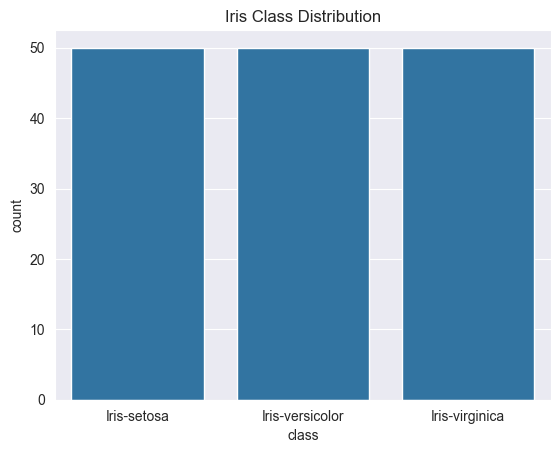

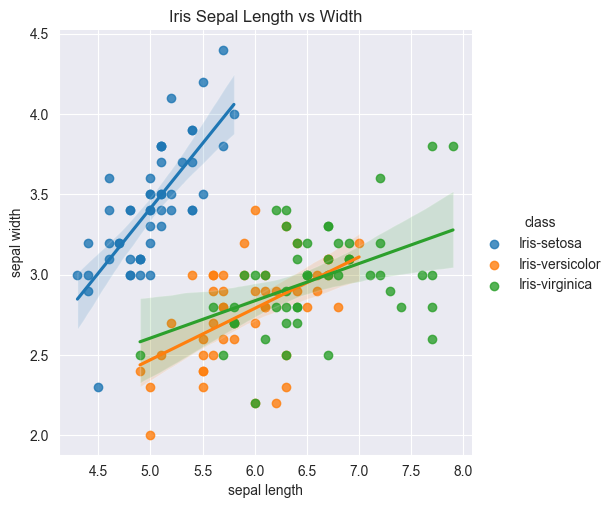

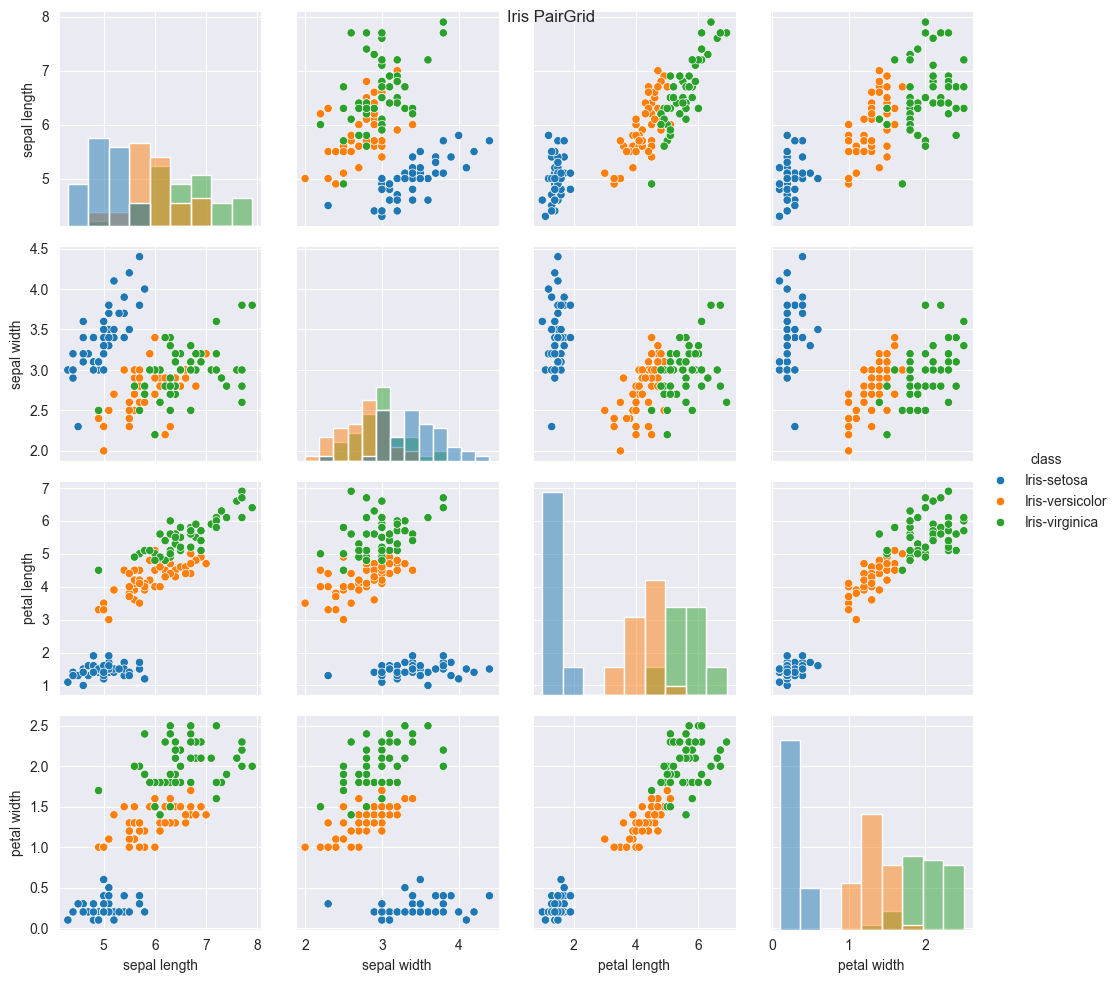

In [3]:
print(f"Iris shape {iris_df.shape}")
print(f"Columns {iris_df.columns}")
print(f"Class distribution {y_iris.value_counts()}")

sns.countplot(x=y_iris.iloc[:,0])
plt.title("Iris Class Distribution")
plt.show()

sns.lmplot(
    data=iris_df,
    x="sepal length",
    y="sepal width",
    hue="class",
)
plt.title("Iris Sepal Length vs Width")
plt.show()

pair_grid = sns.PairGrid(iris_df, hue="class")
pair_grid.map_diag(sns.histplot)
pair_grid.map_offdiag(sns.scatterplot)
pair_grid.add_legend()
pair_grid.fig.suptitle("Iris PairGrid")
plt.show()

**GLASS ANALYSIS**


Glass shape (214, 10)
Columns Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type_of_glass'], dtype='str')
Class distribution RI       Na     Mg    Al    Si     K     Ca    Ba    Fe   Type_of_glass
1.52213  14.21  3.82  0.47  71.77  0.11  9.57  0.00  0.0  1                2
1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.00  0.0  1                1
1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.00  0.0  1                1
1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.00  0.0  1                1
1.51766  13.21  3.69  1.29  72.61  0.57  8.22  0.00  0.0  1                1
                                                                          ..
1.51623  14.14  0.00  2.88  72.61  0.08  9.18  1.06  0.0  7                1
1.51685  14.92  0.00  1.99  73.06  0.00  8.40  1.59  0.0  7                1
1.52065  14.36  0.00  2.02  73.42  0.00  8.44  1.64  0.0  7                1
1.51651  14.38  0.00  1.94  73.61  0.00  8.48  1.57  0.0  7                1
1.51711  14.23  0.

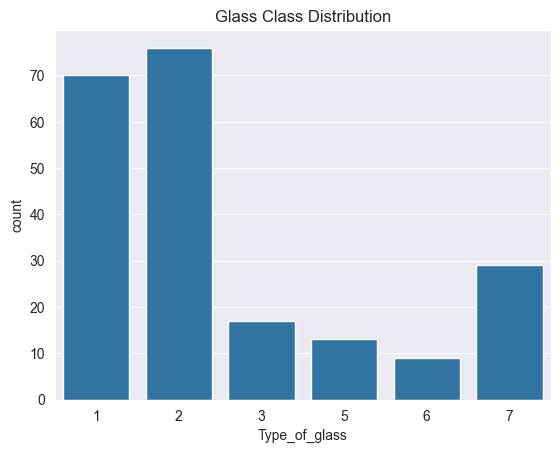

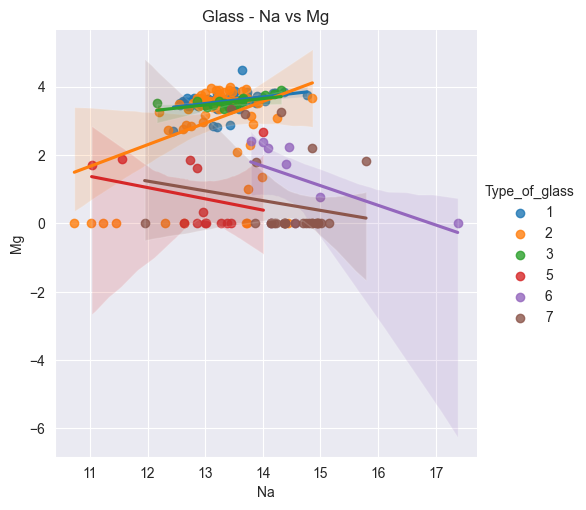

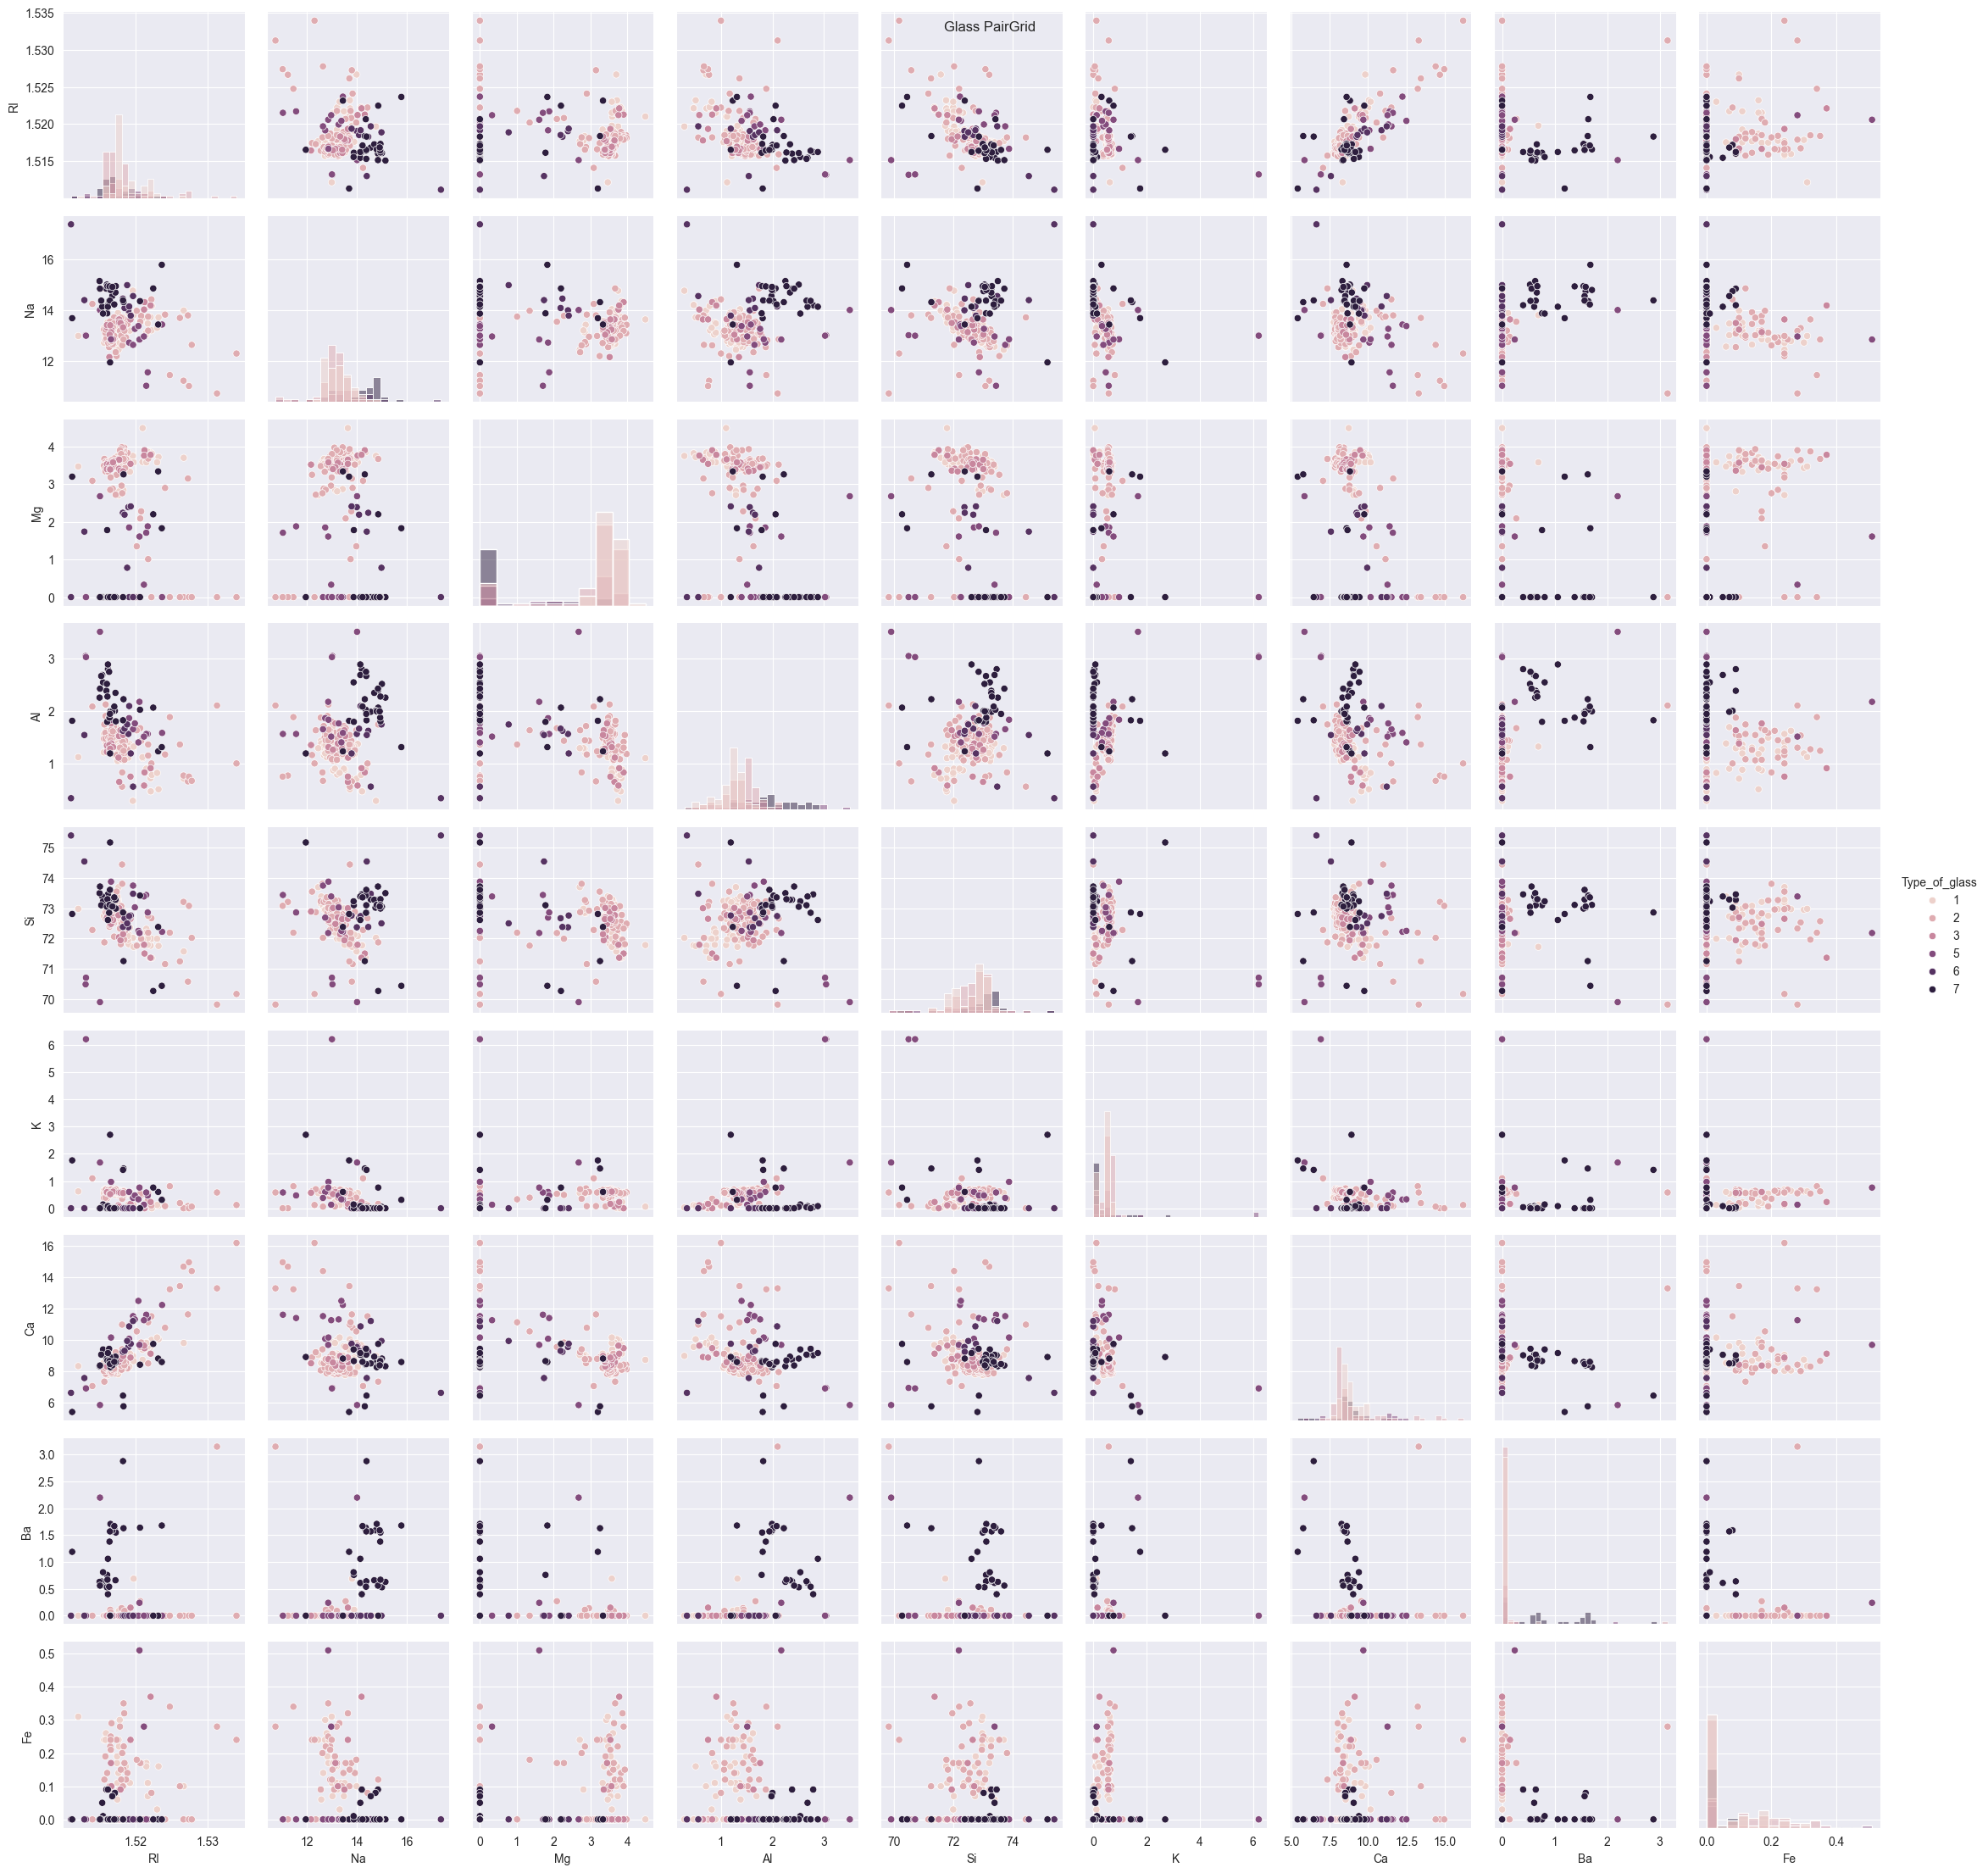

In [4]:
print(f"Glass shape {glass_df.shape}")
print(f"Columns {glass_df.columns}")
print(f"Class distribution {glass_df.value_counts()}")

sns.countplot(x=y_glass.iloc[:,0])
plt.title("Glass Class Distribution")
plt.show()

sns.lmplot(
    data=glass_df,
    x="Na",
    y="Mg",
    hue="Type_of_glass",
)
plt.title("Glass - Na vs Mg")
plt.show()

pair_grid = sns.PairGrid(glass_df, hue="Type_of_glass")
pair_grid.map_diag(sns.histplot)
pair_grid.map_offdiag(sns.scatterplot)
pair_grid.add_legend()
pair_grid.fig.suptitle("Glass PairGrid")
plt.show()

**PCA (Principal Component Analysis)**


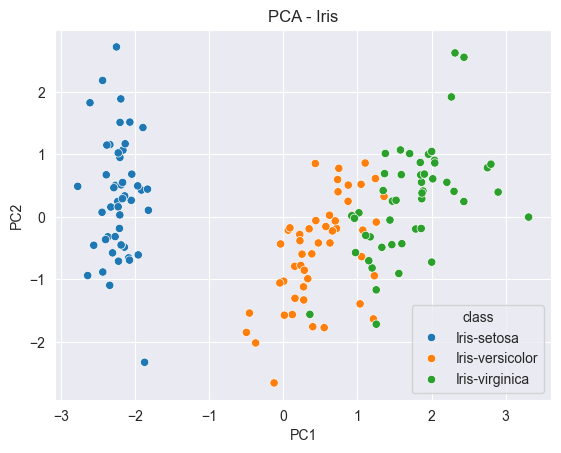

In [5]:
# PCA for Iris
scaler = StandardScaler()
x_iris_scaled = scaler.fit_transform(x_iris)

pca_iris = PCA(n_components=2)
x_iris_pca = pca_iris.fit_transform(x_iris_scaled)

pca_df = pd.DataFrame(data=x_iris_pca, columns=["PC1", "PC2"])
pca_df["class"] = y_iris.iloc[:,0]

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="class")
plt.title("PCA - Iris")
plt.show()

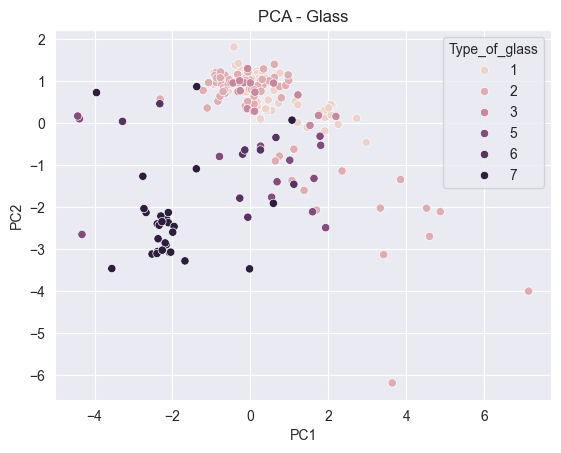

In [7]:
# PCA for Glass
scaler = StandardScaler()
x_glass_scaled = scaler.fit_transform(x_glass)

pca_glass = PCA(n_components=2)
x_glass_pca = pca_glass.fit_transform(x_glass_scaled)

pca_df = pd.DataFrame(data=x_glass_pca, columns=["PC1", "PC2"])
pca_df["Type_of_glass"] = y_glass.iloc[:,0]

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Type_of_glass")
plt.title("PCA - Glass")
plt.show()

1. Czym się różnią zbiory danych analizowane w treści zadania? Na czym może polegać
„trudność” analizy. Który z nich wydaje się być łatwiejszy/trudniejszy?

**IRIS:**
    * 150 instancji
    * 4 atrybuty
    * 3 klasy
    * dane dobrze separowalne

**GLASS:**
    * 214 instancji
    * 9 atrybutów
    * 6 klas
    * klasy silnie się nakładają

GLASS jest trudniejszy od IRIS, ponieważ ma więcej cech, więcej klas, klasy są nierównomierne
oraz wystepuje większe nakładanie danych

2. Czy nierównomierny rozkład klas w zbiorze może stanowić problem dla analizy i dalszej
budowy modelu danych?

Tak, ponieważ powoduje on "bias" modelu, preferowanie dominującej klasy, gorsze wyniki dla rzadkich klas.

Rozwiązuje się go poprzez: oversampling, undersampling, ważenie klas czy inne metryki (np. F1-score)

3. Jak działa PCA i kiedy warto ją stosować?

Principal Component Analysis to technika redukcji wymiarowości, uproszczająca zaawansowane,wielowymiarowe zbiory danych w kilka mniejszych nieskorelowanych zbiorów.

PCA dzieli się na kilka kroków: Standaryzuja danych, obliczenie macierzy kowariancji zależności między cechami, wyznaczenie wartości własnych i wektorów własnych, sortowanie komponentów, redukcja wymiarów oraz projekcja danych

**Kiedy stosować PCA?**
    * W celu redukcji wymiarowości (gdy dane mają bardzo dużo cech),
    * Wizualizacja danych (możemy zmniejszyć dane do 2/3 wymiarów, łatwiejsze rysunki),
    * Usuwanie korelacji między cechami (czasem nieskorelowane dane są przydatne),
    * Redukcja szumu (Czasem komponenty o małej wariancji zawierają głównie szum, usunięcie ich poprawia model(,
    * Przyspieszenie uczenia modeli! (mniej cech == szybsze treningi, mniejsze zużycie pamięci).